In [84]:
import pandas as pd

In [85]:
data = {
 'Suhu': [15,15,15,15,
 70,70,70,70,
 125,125,125,125,
 15,15,15,15,
 70,70,70,70,
 125,125,125,125,
 15,15,15,15,
 70,70,70,70,
 125,125,125,125],
 
 'Umur': [130,155,74,180,
 34,40,80,75,
 20,70,82,58,
 150,188,159,126,
 136,122,106,115,
 25,70,58,45,
 138,110,168,160,
 174,120,150,139,
 96,104,82,60]
 }

In [86]:
df = pd.DataFrame(data)
print(df.head())

   Suhu  Umur
0    15   130
1    15   155
2    15    74
3    15   180
4    70    34


In [87]:
stats_manual = df.groupby('Suhu')['Umur'].agg(['count', 'mean', 'std', 'min', 'median', 'max'])
print("=== Statistik Deskriptif Umur menurut Suhu ===")
print(stats_manual.to_string())

=== Statistik Deskriptif Umur menurut Suhu ===
      count        mean        std  min  median  max
Suhu                                                
15       12  144.833333  31.694087   74   152.5  188
70       12  107.583333  42.883475   34   117.5  174
125      12   64.166667  25.672176   20    65.0  104


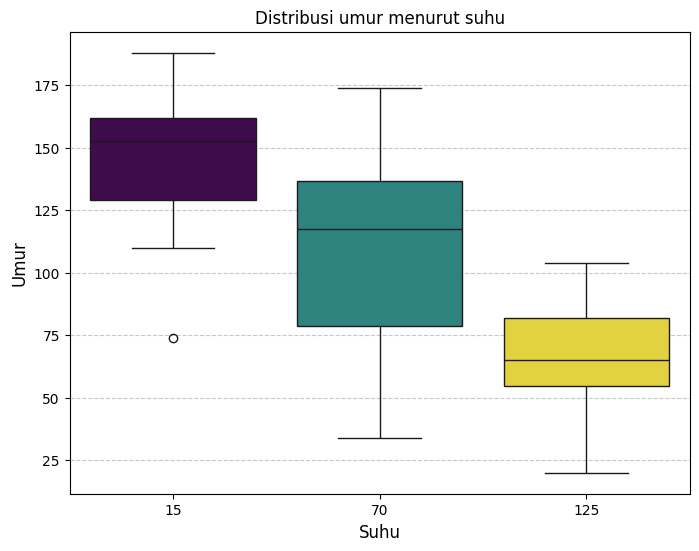

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.boxplot(x='Suhu', y='Umur', data=df, palette='viridis', hue='Suhu', legend=False)
plt.title('Distribusi umur menurut suhu')
plt.xlabel('Suhu', fontsize=12)
plt.ylabel('Umur', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [89]:
from statsmodels.formula.api import ols 
from statsmodels.stats.anova import anova_lm 

# Mengubah model utoma agar hanya menganallsis faktor Suhu 
model = ols('Umur ~ C(Suhu)', data=df).fit() 
anova_table = anova_lm(model, typ=2)

In [90]:
print(anova_table)

                sum_sq    df          F   PR(>F)
C(Suhu)   39118.722222   2.0  16.752874  0.00001
Residual  38528.250000  33.0        NaN      NaN


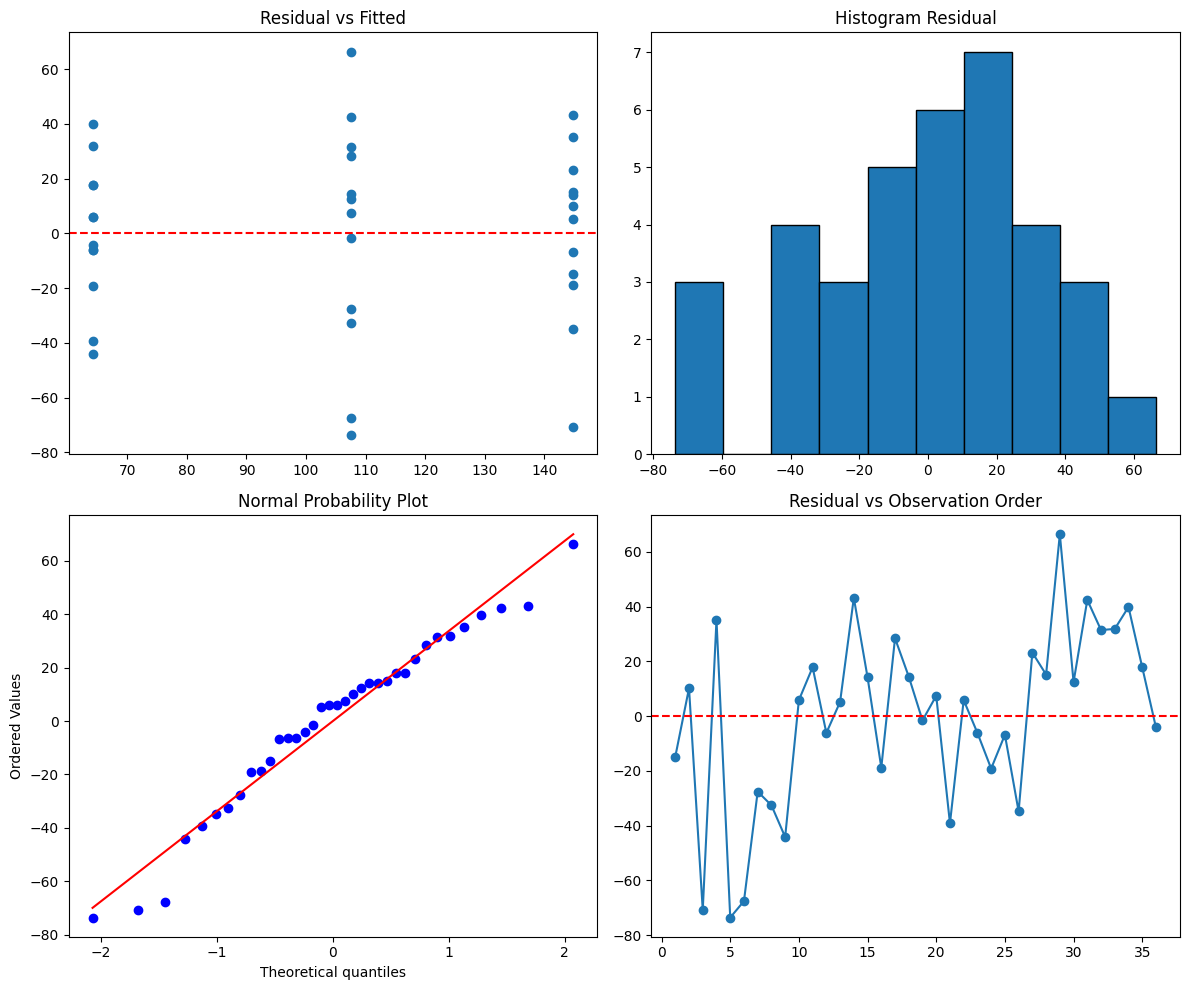

In [91]:
import matplotlib.pyplot as plt
import scipy.stats as stats

fig, ax = plt.subplots(2, 2, figsize=(12,10))

# 1. Residual vs Fitted
ax[0,0].scatter(model.fittedvalues, model.resid)
ax[0,0].axhline(0, color='red', linestyle='--')
ax[0,0].set_title('Residual vs Fitted')

# 2. Histogram Residual
ax[0,1].hist(model.resid, bins=10, edgecolor='black')
ax[0,1].set_title('Histogram Residual')

# 3. QQ Plot
stats.probplot(model.resid, dist='norm', plot=ax[1,0])
ax[1,0].set_title('Normal Probability Plot')

# 4. Residual vs Run Order
ax[1,1].plot(range(1, len(model.resid)+1),
             model.resid,
             marker='o')
ax[1,1].axhline(0, color='red', linestyle='--')
ax[1,1].set_title('Residual vs Observation Order')

plt.tight_layout()
plt.show()

In [92]:
import pandas as pd

influence = model.get_influence()
studentized = influence.resid_studentized_internal

# Memasukkan hasil studentized residuals ke DataFrame baru untuk dianalisis
df_diag = df.copy()
df_diag['Studentized_Residual'] = studentized

# Menampilkan data yang memiliki residual cukup besar (|residual| > 3) tanpa kolom Material
outliers = df_diag[df_diag['Studentized_Residual'].abs() > 3][['Suhu', 'Umur', 'Studentized_Residual']]

print("=== Analisis Studentized Residuals (Model Faktor Suhu) ===")
print(f"Rata-rata Studentized Residual: {studentized.mean():.4f}")
print(f"Standar Deviasi               : {studentized.std():.4f}")
print(f"Nilai Maksimum                : {studentized.max():.4f}")
print(f"Nilai Minimum                 : {studentized.min():.4f}")

print("\n=== Data Terindikasi Outliers (|Residual| > 3) ===")
if len(outliers) > 0:
    print(outliers.to_string())
else:
    print("Tidak ditemukan data pencilan (outliers).")

=== Analisis Studentized Residuals (Model Faktor Suhu) ===
Rata-rata Studentized Residual: 0.0000
Standar Deviasi               : 1.0000
Nilai Maksimum                : 2.0302
Nilai Minimum                 : -2.2493

=== Data Terindikasi Outliers (|Residual| > 3) ===
Tidak ditemukan data pencilan (outliers).


In [93]:
from scipy.stats import shapiro
residual = model.resid
stat, p = shapiro(residual)
print("Statistik =", stat)
print("p-value =", p)

if p > .05:
    print('Residual berdistribusi normal')
else:
    print('Residual tidak normal')

Statistik = 0.9644940322329493
p-value = 0.2945644550274218
Residual berdistribusi normal


In [94]:
from scipy.stats import kstest, zscore
import numpy as np

# Menggunakan residual yang diperoleh dari model
residual = model.resid

# Standardisasi residual (Z-score)
residual_z = zscore(residual)

# Menjalankan Uji Kolmogorov-Smirnov terhadap distribusi normal standar
stat, p = kstest(residual_z, 'norm')

print("=== Hasil Uji Kolmogorov-Smirnov ===")
print("Statistik =", stat)
print("p-value =", p)

if p > 0.05:
    print("Residual berdistribusi normal (Gagal menolak H0)")
else:
    print("Residual tidak berdistribusi normal (Menolak H0)")

=== Hasil Uji Kolmogorov-Smirnov ===
Statistik = 0.11830063915495492
p-value = 0.6515943412224041
Residual berdistribusi normal (Gagal menolak H0)


In [95]:
from scipy.stats import levene

groups = [
    group["Umur"].values
    for _, group in df.groupby(["Suhu"])
]

stat, p = levene(*groups)

print("Statistik =", stat)
print("p-value =", p)

if p > 0.05:
    print("Variansi homogen")
else:
    print("Variansi tidak homogen")

Statistik = 1.0445272045506726
p-value = 0.36320141987586796
Variansi homogen


In [96]:
from scipy.stats import bartlett
import numpy as np

groups = [
    group["Umur"].astype(float).values
    for _, group in df.groupby(["Suhu"])
]

# Bartlett test for equal variances across temperature groups
stat, p = bartlett(*groups)

print("Statistik =", stat)
print("p-value =", p)

if p > 0.05:
    print("Variansi homogen")
else:
    print("Variansi tidak homogen")

Statistik = 2.8321347900170974
p-value = 0.24266645419874927
Variansi homogen


In [97]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey = pairwise_tukeyhsd(
    endog=df['Umur'],
    groups=df['Suhu'],
    alpha=.05
)
print(tukey)

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
    15     70   -37.25 0.0305  -71.4791  -3.0209   True
    15    125 -80.6667    0.0 -114.8957 -46.4376   True
    70    125 -43.4167 0.0104  -77.6457  -9.1876   True
-------------------------------------------------------


In [98]:
import pingouin as pg

# Melakukan Uji Games-Howell menggunakan library pingouin
games_howell = pg.pairwise_gameshowell(
    data=df,
    dv='Umur',
    between='Suhu'
)

print("=== Hasil Uji Games-Howell ===")
print(games_howell)

=== Hasil Uji Games-Howell ===
    A    B      mean_A      mean_B       diff         se         T         df  \
0  15   70  144.833333  107.583333  37.250000  15.393471  2.419857  20.255529   
1  15  125  144.833333   64.166667  80.666667  11.774180  6.851149  21.090538   
2  70  125  107.583333   64.166667  43.416667  14.428135  3.009167  17.986999   

       pval    hedges  
0  0.062118  0.953837  
1  0.000003  2.700523  
2  0.019628  1.186126  


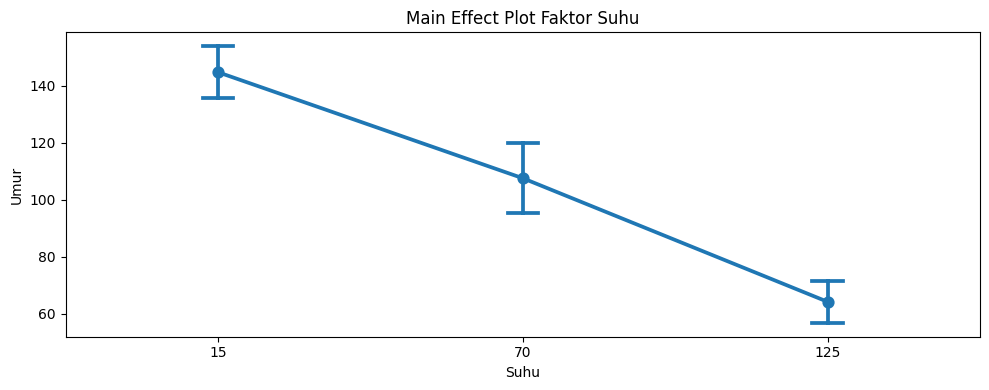

In [99]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize=(10,4))

sns.pointplot(
    data=df,
    x='Suhu',
    y='Umur',
    errorbar='se',
    capsize=0.1,
    ax=ax
)

ax.set_title('Main Effect Plot Faktor Suhu')

plt.tight_layout()
plt.show()

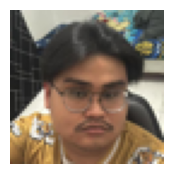

In [100]:
import base64
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt

# Paste string Base64 dari Step 1 di sini
IMAGE_DATA = "iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAIAAAAlC+aJAAAinUlEQVR4nF16aYyd13ne2c+33X32jau4yRItyYxkSbZsy3VleEmcrY2RtnCQwM1S1wlitECBAv3b/mt/FSm6pEUSt0bj2LFjx47tOJIpURKthZS4c4ac4cydufv9trMX57sUY/QDSA7n3pl7znve93mf53kPfPKDT6VpOj8/3+12f/9f/t7HPvaMEAV0zlqrrHnwAAAghAAA5xwhBEJoq8d/0zrg3+/A/cc55yCE/p/qC8IIdABDSKCFmHaL9GJfJVGglS0M7AtBi8laLA3gBatvjwTSYrc/Pnbk8Lh7r/fu26bXU0ZxRgkhZS729/eTWm32+wEABABgreWct1rtF1968dy5Rzin7r3VzBYxW8d76/PvJ4TMft6/VH3x3vbs7GuE0OwN1lpZShLw3mi0fXlzAdP5tdbxJvvRwEkA1f5+/+btMIDJ4+8TlgmDcBxloxKzEBZ5efVNceeeRgAT7JwTpRgMBlEUQQiNMbNVIYIRcGAynmRZNhiMrt24iTAywFjgl/LgcdWZPFgoQghjfP81iABEFjjjrAV+78Y6bY0BTmpZCFGW6p2bu9+6fO98aqIVBu91uy/fqmFcH+ybSU8blGp8q2u6Cu0ODoqDnspVCPHd27duX7+ZytJBAAF0FkwnqQ85If5zZtGylmilQBVBIcpeb/Ctb/31ww+f8i/eX7df+s/GHiE0W/XsAf6H4f1gYAiADwfw27BKqSwrMGLD/ujdKzf64/LRY3Gjrh2GRJj3ZTdsUPbW1k4vgs356GIWG+TOrVGr5ZVJXEzTvTcviumUx7XdnXtLS0vA0clkwhjLssw5Z4whhDDGCISzs56lAbp86crtW1vHjq0rZZwzwJ+Dey/f/KpnXxmjqnOAzmHgLKEUYZxl+Wg00Er7/0I3Go97B32EaK/XFyJfxvbW+Rtkf3HS7RVvbbXPLJ395OOnFiYLk3ohBAFB2e9KmS838O6gn7NOaQAkgVFOSXWw30MITqfTtdU1xhhEQGttjFFKkVkm+5hZG8ex1e673/n+7/7ebwIgrTXO2Vlaz3b44EysQWEUjKd5vzcqVR6yREt9/ca1a9eulWUZRVGn1TTGdA96GCNKA8hoWZTSkdcv71AasaPrj507vLAS15sgq2cP9YL83qVDDzdbAWpEBI/zq9dNY31tmo/LtIQAZWmmlEqSBGOKEJaqfAAtBEC/tFliTCdTpczt23f39/vNVvggUWbZX5WBTxhggUPuyrW7r1++88abV7UztRDK8YHTEhPCeRBw0O32ut09pT1MUUIsBMiBdrsNHO6OhkEUXL4z7iwnISPAltvZ3aOr8VzTRhHvjtAVts6X2eTmNZGl/f4YIBcFNYxpGEZaqzzPIHKMsSAIfA04CI01Uqn5+XlKyHi8d+3a8Cc/ufDZn39Bq/z/L+KqoIw1Fy9eeePSrbIEVqQMqiLPtSoJRvWoFkVJkefD4TDPC3/K1VnPkFcb02w2MYLpePLONTAciNXl5PGzi2dOHQ4jvLfT+5sfbG/Nn7sra4Pd24UDOQlZjTKkkC8+HCcx5zQMA4T8mp1zCHkQ8jUwHI04Y+ura/Nzc8PR+Pz5C89//DmM/h46fSo5iwGa5Oqb33vp2rtbiwv10aBHtCyFBwf/VkzCMPR4J0Se56p6rHNlWfpzoNQ51+l0oiiaTqeD/oGUZbeX7exlu30VRsGdrTF28XJ7Ot2/OSDN1jOfDSd68NMbuBjW4DY1o3o9wRiVZSmEMMaDhNaaAK2AQxBAKWW/3y+KotFs9vqjiz9984NPfsAYC52B1oM9Am44Kv7sW393+erdJORWlTIdK6Gg/2kPSAhhCDFCSCn1Hi5hoxQASGtjrSSEDIfDKpVxURRaTwMu0zTb3DpIOut7Y/PoieX3P/Nop7HdHSbdg362lxsyN78YRWk/mwyzLOOcWetjWe2hKuL3KhMC5yhjRVHs73cxIT/8wU8efd8ZUnUQ4ByG7p3rm1/9xg/3dkcMuziI97am2miIkLNV3wVASjlbutZ6hrmzEpq1QmuclHI4HC4tLWmt9/f3Z1udTqcQQ+1MnfLDD507KFMN0PTy5Xg60nkTkc5csG/LvFcIhFSela7CQK0VhCAOQ2KsNkAT5zsrhKDVallrhsPBpbcuvfrKxWc/dM4Cp4G98Pqlb3zrJ6OJ5EEtIlqrUmiFIPR1/V6jQAgxxoTvXKXygfd5hXwRYwTdrBistXfu3AmCYGlpCULY7/d9ISJSFqVR9vXL7zyyGvbBRvLkSd036uUry/C6Se+Uqd+ktQY6mGVFUWarK+uYt4wDpN1uZ1KJXEAIi6JIp2kYBq1WkxD60vkL7//A+ze3d1985cabb9+uJfMfPre6f2drZ2tLGwl9JPyCZgimtZ4lBsbYQ3WFXb4GPIJ5+jTbpDFmOBwSQlqt1oyPUEqBPz2hhNh65ZXcFs2P/LMAp8OtSx3YT4d79wbdZhI0W81JzgsX0xAGELhA1ltRgY/CZ59+utS6LIs8y5uNRpqmfqMQttpthNHa+smxjnIhyzIPKem0yWR/pxj3fdjd36OTMQZjHEXR/Px8q9XKssxaOxz6rK1S1mqtq5LWlPkkxhjPtpTEsT+ZWco562GXsdXHHj169MRwn93Y2l+Iu4nee+x0vLJAd3vubr9+4Z3UhodXV9fF/usbC0Oile73e2EYwiprq3V5emaMOejtFxJ89pd+7a1L13fKidJ2d3MbiHEFSBZUjEop5flmhZJCiAo9c875jCkFQVAUpbW+o3POldJKSlttXSmFMTZhGIVhnufGGgxxwKnR+uDV1zs23h2Yxw9PnzxTWI/72fJc0AjhRx4ba4l/9Po7j3385GTxia2Lf0zCKJqDc1LKPMs8xZuxIOeQhxBS5KML539wd6cHHUyCwKm86oAWIU+DjDEVq0MPaCtCEGNf94yxhYWFwXCQZqnxR4oh9C/5KgdQaz1DcVgdIcbIfwc6jZwjwFn49ms/jhobp54kd671e0Nx5vTc1Rsw5GinV97cMnMr61EYXrr50vGTa2Tr7p1ardZutcIgABAUojRGe0zxvAwZoa69fdkYGwZcuwACo42taKCP96xqrTW+sxjlHCrLAmOCkO88ECIpSowhgsQZCwEgCAGCjWd6FmPfgqQUhOAkif3hKGm0P39Pz6yV+b3XXienHqrPdeK7mwDR6bSwhiQgqmlYv7k5bNTQNA+IAyDLMiml0XphaXF5eTnP8iLPH9B9CxCPapwTjKE1lmCstZZSQggZY8YYOAvjjG5Yp33hmjiOnTOcMGkLKQTnBEIQJr7NFUJIz8X8m6VUzqZSSiFE9Tv90VnryabO1OuXxFvXDp44Pf/+M7UA8bV1cvWue+26qTfdiZMbP/72q4+sT4gDzkMdhFKpwWBQCsEojQJfjpzzwWBgfMTMDBJ9+3ZuBvaU0hnSW+tLkGAfa78zAKI4MkpgB0xZIi06ScgY4QFhFGMLylKmhZwKOS2lLKQwDiBrgDPGB19Kj2bIpxeCMMgKNRjbr31n/8g6S263XnqXkLglo6P/86vfewi9M7Gn4ZFjRzHGlNCyKMIoKsrCl7KxnU5nFtQgioCVUsgZ7EgprbUz7JudEoSAEGyNgcDztiqvaKMeh4SK6YRjECdBIwoaIW0kITRWajXJylGpRtN8OM1HmZxKXWolPe1wPk4Vu/GrohRT7KUT40In0oEwaQTtU0IJNrzw7PvDV7cxscYgAGEF09ADEEAAuqpHKqWEEOPJZHGxwzhTUmrtEZZUq3zQAXwJV5Xhc8wTPgctAFppVdYYSALaagSNkNUDOt+MY0omQoxTVpuW7YANIzbIxMGkHKblyJa5EBAACqlnflWhE0sIdcuLc0ePH0c0Riyyxqpc1E8fL605vmbJ8tLyDK1nzwPuOft5vynnjDYzHVbJg/uCfSZ8fSfz51/91/lPptDFGCGRJQFrJbxVi2pxkHBW5zQmqBXyJCDNKKjF+SQrY45CSjlCIYGcuv2xyoRvGoz6PcxQzmjVbtU++qGzoS8k/6nOQp93wCHkPLuKomhurt3vDzAmQogHYvw9peaMNUppaywAkFJ/WFXt+iB5qgwRJv6cOUIMuCSgAYU1RhoRr8dh7NdNY8Y4gc6XCAoDXtG/kCHECcGkgAhSijiDyhqhhJfUxoPsTIAggJyHRURoCHElCY3/BkS+eElZltp3Ys9+W632zwr5IAgqLuBFHQBWKw0ArFD+fh/22/DIDygCDJgQujpntYiGlAQUJQENKY45DRkhwDgLpIGZEcr3BWcBJIRyopOASB0gCAJKpQLD6bBQGkB4P37VBzUbDYIJ4/RntPj9NPGHAgCglJVlmWVphYf33Yd2uzWLN6Ukz6ZV5viTqdq+/+OJGoQMugChhKB6QBshjwNKIAg4DSgOCMYAOqM9I3QQQyyA1tIBCB3yaeCAZRglnAILCNaLdbPZSwufseiBd+L3xhilWGvDOPdJVOWwpyQI+/V5TAZgdXWVUjoej/LcawbnXK93MJ1OMca1Wq0isRrj+6lpjcUAYqhiQutBGHGacJJwEgckZDSkPl8YgQHF3qkw1iJf656jQI/xFQZAqZUnURAHxGnm7bEkpjFnw1xW9TWTU456aMP5dJpOXBiHuMLrqolXttDMLhkOB8PhYGFhwTmXJHEQBI1GI8+z6XRqra8qjID1BasQRP5TvUIAjdiHvBbzmBG/h4BHDAfU74EiFDGMMMAIEkgc9DWD/LogRtgH0rcfVGKjtHcNuI8K9AUTMP8+L49m/o1PotdeffPKW+864DABGJOZwRCGvN6ok8XFeaUUQijLMq/rp6kQAkKQ51mtVntgB3lC4Ly9ZJ1BEAWEtiJSj3kt4jGnFANOPYUIOI84DhkJA0YhwBj6EgfI2PsMinMSBf6BwAZSC23HaQksNMRJ5Sg2zSSG+wPk7SXPwxkhnFHPYX0qASWttNpaYK0bTcT23oh0u90ZEw7DsF49uWcSGcYkCAJPGKtE9MGEwKec9Vk7Xws6CW/XopATIe0wK6WWFGfz7UYjYI0YeSuUYe8PVY4N8WQOYYSYr2/MMDAOQQd92BE0COXGFdrzukbAkLdbHSUIEdSIo06r1mzUEZiZmf4vvwFjNbDGWeIJgnGTydQY6xyciSmEUByzer0+4/oew5wNoASOTPMipmh1sdnieK4WOwBvTcfDVAhrCEa9tAsxJBi3o3ChES00a42QJBQ1gmCGHFqZHOhMaqvdMBW7k2wi1f44P5gWUIF2M6aMNuIwaTVWl1bGo/HxYxvr68tB4Cn3TDZVrMmrC22M1RoePnz4QZ602+2ZoTDTh61WYzQa1ev1NMuOLHYOWaspSwHsT0aPn1xfqvvGIqQe5qXnS8ZkQg3SMi3FKFeF1AgATlE74Wut+onFdrvGPS0gsJR2b5wNM7k5nBxMM609gxfOMchaNXpoebGgweLqSqvdVEqdOvnQ4cMbURQVRYGQx1bpWV/FuSBQpSCVeXh/C5WL+PfPffvWIQ/J2jYQihI+YVg6Nc2K40ttAKzUJia+NqZCEGMi5DDHESVZ6eUmQoASMsqynQGisM4ISbW6ddC/ujtJy8oOATAkJAl4J2QU0TjkrU7z2Wc+hAlZXJxTSrZbrTiOiafe0ay3csZm3uh9h3SW5bPXbOUvPLCCZiausR7HT73v9IaRMBtraz5wYg0Qeu3u7mq7prQSyhyM00xYYYHQzpeYA0p70cwJCREIKbbAjXPhbJ5qO0lVgDnkWFlNKA8p9qhFMSWgHoHF+c5TTz9pvM70ZIz5x/cvhPCsAHz3rHqob0XWksXFRc8COB8Oh5wH06nHop/xpZ3W6vjRQ7/7+/+i//KFt7/7l0WaPXR8ZblVf0XJ/nTSDHmuAa43eS6m47FDiBLqqx1hrbSlJPVBAgxV1hAEyu9NlyonYRKSiAdBZWdDFoaNiDkC3rhya/7lC5/61AtFnkmvVxHwppTzpv+sr2FfwF4G+iNwZHt7mxCysrIymUzq9ftdevYwxuqNxpHDh3//y79z6Mih/NLbo0laKuMD5vSjR9a++8aNSze2VzqtThz1hYCYOIeFdTvdg3az7mVkKefrzBG6M5rEjFqMJ1nZm5aacFFqSxBG0hiNMKoFtM6Tcx95uqDRf//jr27dvffsh54+evRoFAZlpa6qpPYU2Bjf5nBFiqQsPTF+UN1VB5i1D08l8ixDCH7xi7/x+GNnnbPIScZ5Mww4QRq4OtPPnli+yEGNkZgSHTNGcKFsWqo04e1mnKeZNa4RcB4kuixW2m1p9bjoOsqsw+M8laFtxc10PK6FQaeVhJzc2dxtHnloOJz8n69985ULb8zPzz3xxNlnnv65jfU1IQQwekYxhCwrFxDk1vhO7JybNYE4jisbUM/OIUmiL/zGPz33xFkpRRAyZO3SQifm2P8iQCFECyE4d3ihFAABi7HLmS6kCREM5ttaq0YUxnMNRtBE6EOtZL0VDfIMObfaaaRC1nmLcsScOLYyX4/CJGIBQQcH+xdv3F1bXlS+bZHtu3s3rt/+9rf/+ud/4dOf+fQLlCCnvQhxzng/EwAa+AGHf2YGScVSZnYPoBR//vP/6DOffsFaRQgxRtXqUbOZ+HkSsNgBAhHkJLZYK1njHEGb4bIkuklhGVGlDHYwDPgoL5Vv4JZiMEyzQVGebrWWa2GmASYw4iRmPGY0DjihUGuyzJL23NzBaCqFzDKNIBn20z/6z/9t6/bml770255GKMO4ByKP9feVWCUUhRCMeRu5yAtn7ed//XO/+LlPIugVESGUch5GLE6CUVbYaqhTeaaQIJdLkXAceLoelkjkwDHgcOAnEcDTl1BnRZ3zer2+mGdH5putiDeCMHdeSUPkqXjEUMIIxGjqXGg1D2rxoZZzdjKZ3ru3u7u7hxH99l99b2Fx7tc//4vOn/b9MWlZFvc3MEt6jHGS1Kw1zz//oS9+8Tdm4roihpUCAS5g1E5Ta5G2BvkuDiLi2mFQOkSc9B4wwgFlnFAArZbSQMSjZBmTlWat3YjiYDUtTKb8TDDxsAgxBgyTkFIInEIojCI76r+z2csBCQJGKJubm0uS2ubm7bx0f/anf/7UuSdOnjrhGXnVBGYE8WeGAAAO+sNHzpz87X/+hSgMESKz6ve6Tgkwt9LLC1EqCInHeqM8z3GgTpEEiERN30WcrZLQamU0ICCsF3keYRcQyCBYbLU2Ftq5Eplx2hjoNPPCjMVhlCRJfWGFQwut2Onu7+1197r7BwcHvd6BtXpjY51zPhql/+W//sls3TNZG4YxeRD7MAwIJicePvyv/vWXO+22t9wIxZgwhr0qtnr+fR94srPyzt9+b/fSaw7hBzY6wq5pxEgDVG9CbYCU1rMpCBG7s7XXgiKOG0kUNeIGBG51obk7mu6m8sjaUhLSgFLPI2v1+uLava3brJyUpeoPh5CGSnvSwBmTUgZhMD8/J8rdC69efPHF888++6SsHu8wzPyFwXBktFlemv/KV760tr6CEKY8cUW/2Hl1VBq2cLqzetpBOLdydOXUwzuXXnEOeTvDecokHWQUJNl0ONAlotKPmP3Uar8/qGH+8OHVOAgSRkvPcHEtZE8+tPb6le1727uLiwu2EYhMHAzvBjvb3AhozbgU07zk3JNYT5rfuyoQhmEcBYPh+Gv/9y+effYpgkPfD6X2J1CJgeLQ6sJX/vBLJ08ecwBQaya3X+rd+MEcH914t7s3Ch/56HOLnaaV5Xhzn2LqiaD1msa7KNVnUYoX6l4zWIeNhcOpSoFtcWKU3BqNGIUx55iS0upC6BrHQkg4OhDTIeWEUGQJLRFUCPVGWSmk1x4zw9p3W09zEEL1RjIap2+9dfWNNy4//cwzZZlFQUA809H2yMbGv/03f3Bqfpzf+rrTEJZ7+mA7cpyuPX/v1b+e9G50snfDyiyqOYsZ1sI66y11I6UzztcS8MhMfAHAUumYoKW5zl53fP1gOMyLCOFWrYYonhSFMfbhjaV2oyGUghjDCqs8HXNAAbd1r2eVlcgAISqCWVmHAAqIGGdhwPJcfOMb33nqqae0VmHohy3m0ZOH/vArf3Bqo/7iV//DfDt4+MxCwFgeQNA4gzd+gS/eORJPnfXGK6KsHqgkgCNRkT/PyQ2wyHkD3ctO5YmLH2PGEQVhONVo0B9RiLR1A6WtUgEPWgFmAU3qdTcaG60dwT5ZULUBA2jECAZKelXoVZRnrF4dKU8fUK0WFXlx/uULm5t36ok38eGXv/x7v/mrn2CTV5badm+7t715cPzEPOcuoNgsfTpPHh7e26zH5Ma1K2z4041FAFhz59bozu2hn/gY69WTRkZ7NuujibwVRhlVhmwNRsOydNpC7WpBMJ6mBiHKaFGUCKNjq/NNzkVReAMFAYuwRbBQCjA9LMRrV/a2dqfa4oBzSiln1LPSgFPO9nZ7Usvf+Z0vfP7XfsW7ms8++9y1rv7EB1/QW1/HoDz7+EpRKmBZIcX+wWS1Fdwd3tm+tjvS7UNR+7U3NumZp8vsgnXGGSCNH5Qbb7l70cscBRhaTG7vT3f7UwjAodX5OmbFNNPGNtodB4CwCiTh3jR95erWUqO2Mleve7Lt/StldJpn5XR49PDCSmttMFVv386v3B0WRiIDkcFQKUQRZURq973v/+jTn/lku90i3/r6//7YJz5b4g8W4YdHkz8dZ73DRxcmvTxZXF1YOcsjUtJDb29tnZu/zlGvuzdoBG+W4y6D1hjsz8A3OA8DxNtzSFh3Z39052BKKFlt18eD4fVBmpfK+TwDnDHt3+xW5tsLrfbWwUE/TR87shJx7N04paHvl0hKDY1drZGNc/NPnl54+cr+jZ1MVjM4rbSf6BRy8/bO1as3n3vug+jn3jf/3Ec/bLXeGREXBKOJGg2L4XiCwyWWNMs8/cmP//zi2zfnjp4FPFFCQltKHufSKy5ovdED/LgcM8840DCT28PUIWS1emdz+9rWgTV4IWquxe2VWms5bq3EDWzxzTt7w+EAY2Qhkt6jB8ppP1ZwmhJcFMKzHQiNFOsd9/mPHfrch4+067wU2mrtPRAEpRQXXn4VWEMYFi+99OILz3+s1lkSxXE8eq27Ny2kXKPz2CA13Xt6dUTs/N+8NThZ4yeOr13YRe9/6vmtwVelEdz6Mctsou0pnrUQ2HqAtQXYkXaQRAQHGDd4GHGmjfT+JibLqrYr0lQWLUQj7n0kaWyp5f5gME4nELojG50SiyT0M7VCGOgmj2yEx9cOXbiR/fTqgbY6DJnJ9Esvnv8nv/6r5Jee7vz5+Rd/enl+aXn56o1pR1gBRH8qGgdgoyWbC0c7xz8Vjq4OhoPvX9neG4L5hajb7Y5GKVAlAXEzDLGFCmnv7SgLjJmPg8o580orE2IwGfcGHmf9jGlmrRAUJmylEcNK9JWiNM55gxbqwuhTR+ZCTnr9DHRAxAmybpqpYqhazfATj0Yn1w798I1BIT0D2NvvvXrxLXjjm7/FKD9/VYgcLMWjAKNRKgbDfBo99A9/5bfWDh3Js3L77t3bt29d/NG3jz36zPTuS9lox02zQjlWX6dlir2kwlZbUQo/rkRw1qG9noZWC1MW2m8NOwMNxTSkjFGI/bURABGS1mRKN+fmdrvXu7303MMr6bSknENkAkaacQSQ6/YzB8HSfL1dZ4A1f3R5/J3zV52FH/3oh8jWnenqgn1kUfd6oySI9gZpf6yadbZcm/7JH/37QQrOPvrEoWMn+9d/9OiJpU/948+88bdwMBr377x77a2fWswMJvlkignxrNBfPasGZtoihuI4CDlTQqvICGu9zeKdRgS9TS219xGs0zYt8nBxubU4v3n3chJ6/T7NyzpGjANKYV7kjLP5diMXQis7SXWrPv7cU4255MxfvLj16sU3STEd72iZJEEp3CSb5tLt9/JaXItIeSIY4kY4uPs3r7397U//g2N/9dq9vYP+2kNPzglxfvNGlqYuHLTi2FtiSiOCqb/N5rzWwYQSTCkMGQgJK6i0ynMOUs1kjYHCQWVBKWTh5Zx96OixfHLPWlirBZhAC1x/nC3NxXEUlIW/OqZFagGYZFLqAEJn3ODjZ9onVk59/XyX1CK+28vSihFMJuX+qJikkpDk+q1uwOj6cpJfv/f8xw9jZnbubH7zf/zHoH302JHm/s5l7wxDSfkc9J3U0wffSF0ZsSDhnFpblEpVbp82NpM6k4oSX8TOWWl0Vso8L60zG0eXG41G9/brTrl6LXTAxFG8N0itw+m0VMYQTpy/+YMIgrVaWK8F2WSyr0fL9eALH18gWvnJ6d5u6gAxxqWZ8dcWpOuPxNoSyaajDzyystfrjUbm9KJ74Zz5/mt/d6PLjKy4BJRJsz7tElM4YqGDUFo9zNNCy4xSXvjRqs8TAAyApVReO1cT4qIoldYQwVYdL6xsCCHzyRggkASkFFJpHTLsWYMHpZCG9Qq9vHKhzHFsaCPyk2FjOnVC0tIZaYwEU6l6gxHwBjYsCuss0NrWG2GvP7221U+SJOBYFuWJBWIN/OGWqaQLgjxMmrFQqbPQWsARZQwXWk0LjT3o+OEI8H4OMBAqq7XSyN+MsZw4xm2j3WgtbmzfujzJ8qhGAbClMJM8X1toO13kuHHkzLP1uXlCuZL2ytXrUNyJcWadCgMKnUSIESF1qTRErihybUGWybWV2iQVAYVnjiyWRvz45VvnHj3cneZJEBSl93IK6bmP71/AARxBgmLm20EptPatAMTVXV1htFAeWv0E9r2LOZ4mI0cZ4tS1m2hp44TWpr97W0hweLFWFGWaaQxRLaajTHUOn+Xx3N+df7Xd6UDp7h5MTOhcmpG4c/zYkfl42AoBktJIf/nJ+okHgrmStYDkWZkkbPdg8pffv0pIMDcfZamgzN8e5L7t+1Gxhx0tjHM07likGEYhI6y6IOUtS2ADAusBizEMMGTID2wYhhQ57oubtOqk0+nMrZzYvf1Wnma1mAYY5qUeZ2WjEafC2dqxIGlde+vH0XTz+k9+mN9++VDUq2N9c9i+o44uPvaLo+CJPDyNcuHNnKxQ2vvt0GijtNF+qgVeuXSvEHh5MaEUS2EZJda6OMKMBtY6T3WBGe3v1NtrRV4ap4KAJgFNwoBSBgFE/o6K8bcHKKJ+6ZBiGIWUM9JIUKMRLz709HTS6+9tFVIvzjW83q5GpM0G3z6Y2DB2wN3cGa+vrR/ukCiOcDFeRZMjS3x+aeHlC2//7Ruj6OQvk2khykIJqb2frGGNh8A6qUG3V/aHxdpSy0/XlCMIRhw0m14DMe5vumqjiB/nudWNo9feamejEcXenENAY0wsRa66KTi7XDMzW4ED2koeolYDzW2cjpL2tVf+Kk3zOKCckv7Yx7EWEO3YsYefHkv00itv7gzyteOnd7e3tsfFWtKIiKJhnZu70ah4bDX4X//p36FBPxtnYpxJobTy/UUbA0pl9/sFZ6yZBDu7oyxX882wlrCkFk3T3BjLCSb+KgDe795rtJtnn/poMrc0TDN/RcXfCnEMw4B4nz3hLKY0IiSo5HethufaqLP60OLRh+9df3Uy3lPGLs01S48+1kHLgzCYO9NYOHTvxqX+7h1Vgu2xqS+uLoQMODtViCZLTz73y098+GOrwbjjNlE6kLly2icPKISZaiAgzUtTSJUkgQYwk6pUohZz68D23d6gXwCAGEU8pJSS3u5ev9ddWFk7/PDZpeMndRAab3FQPz32NQWZN8ZwdW3OJgls1Wm9s756+unR9s3B9vWi1HHEw5BkQkllYk6j5uL68UfGvXvHO/bMkTZl9PqNLZ3nG53g8JGT75qjJ8995OipM3q6tb0zOHv60P8DKc5z3+7sWmsAAAAASUVORK5CYII="

# Decode string langsung jadi gambar
img = Image.open(BytesIO(base64.b64decode(IMAGE_DATA)))

# Tampilkan gambar 64x64
plt.figure(figsize=(2, 2))
plt.imshow(img)
plt.axis('off')
plt.show()

In [101]:
from scipy.stats import dunnett

# Kelompokkan data berdasarkan Suhu
group_15 = df[df['Suhu'] == 15]['Umur'].values
group_70 = df[df['Suhu'] == 70]['Umur'].values
group_125 = df[df['Suhu'] == 125]['Umur'].values

# Melakukan Uji Dunnett dengan Suhu 15 sebagai kontrol
res = dunnett(group_70, group_125, control=group_15)

print("=== Hasil Uji Dunnett (Kontrol: Suhu 15) ===")
print(res)

=== Hasil Uji Dunnett (Kontrol: Suhu 15) ===
Dunnett's test (95.0% Confidence Interval)
Comparison               Statistic  p-value  Lower CI  Upper CI
 (Sample 0 - Control)     -2.670     0.022   -69.463    -5.037
 (Sample 1 - Control)     -5.783     0.000  -112.880   -48.453



In [102]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Cocokkan model ANOVA satu arah untuk Suhu
model_suhu = ols('Umur ~ C(Suhu)', data=df).fit()

# Definisikan matriks kontras
# Urutan grup berdasarkan alfabet/numerik: C(Suhu)[15], C(Suhu)[70], C(Suhu)[125]
contrast_matrix = [
    [1, -0.5, -0.5],  # Kontras 1: 15 vs (70 & 125)
    [0, 1, -1]        # Kontras 2: 70 vs 125
]

# Jalankan uji t untuk kontras
t_test_results = model_suhu.t_test(contrast_matrix)
print(t_test_results)

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0           203.7917     20.924      9.740      0.000     161.221     246.362
c1            43.4167     13.949      3.112      0.004      15.036      71.797
